# Función de desempeño de seguridad (FDS) para siniestralidad peatonal en Bogotá
### Poisson / Binomial Negativa / ZINB por segmento vial, con validación aleatoria y por bloques espaciales (v5)

**Correcciones incorporadas:** verificación de la BN y dispersión, regla de decisión declarada, diagnósticos de ajuste, errores estándar robustos, Moran de residuales y validación por bloques espaciales. La longitud entra como covariable de coeficiente libre (`LONGITUD_LIBRE = True`); la tabla de coeficientes corresponde al modelo final seleccionado (con ZINB: inflación, conteo y dispersión, EE agrupados); la sensibilidad compara Poisson, BN y ZINB con offset y con longitud libre, y declara la regla para elegir la especificación.

## 1. Entorno y parámetros

In [1]:
## Librerías
import sys
import warnings
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.font_manager as fm
from matplotlib.ticker import FuncFormatter, NullFormatter
from matplotlib.path import Path
from matplotlib.patches import PathPatch
import os
from itertools import combinations
from mpl_toolkits.axes_grid1.anchored_artists import AnchoredSizeBar
import json
from datetime import datetime
import joblib
import statsmodels
import statsmodels.api as sm
import sklearn
from scipy import stats
from scipy.optimize import minimize_scalar
from scipy.sparse import csr_matrix, diags
from scipy.spatial import cKDTree
from scipy.special import expit
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold
from sklearn.metrics import mean_poisson_deviance, mean_absolute_error, mean_squared_error
from statsmodels.discrete.count_model import ZeroInflatedNegativeBinomialP
from statsmodels.stats.outliers_influence import variance_inflation_factor

pd.set_option('display.max_columns', 80)

In [2]:
## Parámetros del análisis (todo lo que se ajusta a mano está aquí)
SEMILLA = 1949
K_PLIEGUES = 5
LONGITUD_LIBRE = True         # True: log(longitud) como covariable de coeficiente libre (v5); False: offset log(longitud) con coeficiente fijo en 1
COL_X, COL_Y = 'x_m', 'y_m'   # centroide del segmento en EPSG:3116
TAM_BLOQUE_M = 2000           # lado de la celda de la validación por bloques; se contrasta con el correlograma (sección 8)
K_VECINOS = 8                 # vecinos para la matriz de pesos del I de Moran
N_PERM = 199                  # permutaciones para el p-valor del I de Moran
N_SIM = 5000                  # simulaciones para el IC de la elasticidad total de la longitud en el ZINB
N_PERM_CORR = 999 
print(f"Python: {sys.version.split()[0]} | statsmodels: {statsmodels.__version__} | scikit-learn: {sklearn.__version__} | pandas: {pd.__version__}")

Python: 3.13.7 | statsmodels: 0.14.6 | scikit-learn: 1.9.0 | pandas: 3.0.5


## 2. Datos, offset y covariables

In [3]:
## Carga del conjunto unificado; el índice queda 0..n-1 porque las particiones trabajan por posición
df_unificado = pd.read_csv('Data/processed/segmentos_unificado.csv').reset_index(drop=True)

In [4]:
## Verificación de columnas, de la variable respuesta y de las coordenadas
COL_DIST = ['dist_puente_peatonal_m', 'dist_puente_vehicular_m', 'dist_semaforo_m', 'ratio_cobertura_peatonal']
COLS_REQ = COL_DIST + ['MVINUMC', 'MVI_VELREG', 'long_seg_m', 'n_siniestros', COL_X, COL_Y]

faltan = [c for c in COLS_REQ if c not in df_unificado.columns]
assert not faltan, f'Faltan columnas: {faltan} (las coordenadas se crean en el cuaderno de unión con el centroide de cada segmento)'
assert df_unificado[COLS_REQ].notna().all().all(), 'Hay valores faltantes en las columnas del modelo'
assert (df_unificado['long_seg_m'] > 0).all(), 'Hay segmentos con longitud no positiva'

print(f"Segmentos: {len(df_unificado)} | % con cero siniestros: {100 * (df_unificado['n_siniestros'] == 0).mean():.2f}")
print(df_unificado['n_siniestros'].value_counts().sort_index().head(8).to_string())

Segmentos: 131704 | % con cero siniestros: 89.88
n_siniestros
0    118382
1      9826
2      2062
3       729
4       332
5       147
6        85
7        41


In [5]:
## Respuesta, log-longitud y covariables: log1p en distancias (se estandarizan por pliegue) y dummies de velocidad
Y_ALL = df_unificado['n_siniestros'].to_numpy(float)
OFF_LEN = np.log(df_unificado['long_seg_m'].to_numpy(float))
XY = df_unificado[[COL_X, COL_Y]].to_numpy(float)

X0 = df_unificado[COL_DIST + ['MVINUMC']].copy()
X0[COL_DIST] = np.log1p(X0[COL_DIST])
DUM = pd.get_dummies(df_unificado['MVI_VELREG'].astype(int).astype(str), prefix='vel', drop_first=True, dtype=float)


def armar_disenio(pos_tr, pos_te, libre=False):
    ## Matrices del conteo (X) y de la inflación (Xi); el escalador y la media de log-longitud usan solo entrenamiento
    esc = StandardScaler().fit(X0.iloc[pos_tr][COL_DIST])
    mu_l, sd_l = OFF_LEN[pos_tr].mean(), OFF_LEN[pos_tr].std()

    def _X(pos):
        X = X0.iloc[pos].copy()
        X[COL_DIST] = esc.transform(X[COL_DIST])
        if libre:
            X['log_long'] = OFF_LEN[pos] - mu_l    # su coeficiente es la elasticidad con la longitud
        return sm.add_constant(pd.concat([X, DUM.iloc[pos]], axis=1), has_constant='add')

    def _Xi(pos, X):
        return pd.DataFrame({'const': 1.0, 'log_long_z': (OFF_LEN[pos] - mu_l) / sd_l}, index=X.index)

    X_tr, X_te = _X(pos_tr), _X(pos_te)
    off_tr, off_te = (np.zeros(len(pos_tr)), np.zeros(len(pos_te))) if libre else (OFF_LEN[pos_tr], OFF_LEN[pos_te])
    return dict(X_tr=X_tr, X_te=X_te, Xi_tr=_Xi(pos_tr, X_tr), Xi_te=_Xi(pos_te, X_te),
                off_tr=off_tr, off_te=off_te, len_tr=OFF_LEN[pos_tr], len_te=OFF_LEN[pos_te],
                y_tr=Y_ALL[pos_tr], y_te=Y_ALL[pos_te])


def entradas(m, D, parte):
    ## Devuelve (y, X, offset, Xi) de 'tr' o 'te'; el modelo nulo siempre usa log(longitud) como offset
    off = D['len_' + parte] if m['tipo'] == 'nulo' else D['off_' + parte]
    return D['y_' + parte], D['X_' + parte], off, D['Xi_' + parte]

## 3. Modelos candidatos

In [6]:
## Alpha de la BN por perfil de verosimilitud: se maximiza el logLik del GLM sobre log(alpha); no depende del optimizador de NegativeBinomial
def alpha_perfil(y, X, off):
    def nll(t):
        with warnings.catch_warnings():
            warnings.simplefilter('ignore')
            return -sm.GLM(y, X, family=sm.families.NegativeBinomial(alpha=np.exp(t)), offset=off).fit().llf

    r = minimize_scalar(nll, bounds=(np.log(1e-4), np.log(50)), method='bounded', options={'xatol': 1e-4})
    return float(np.exp(r.x)), r


## Ajuste en cadena de optimizadores (solo para el ZINB y para contrastar la BN de statsmodels); maxiter explícito
def _num(a):
    return np.asarray(a, dtype=float)


def _fit_robusto(modelo, start=None, plan=(('bfgs', 500), ('lbfgs', 1000), ('nm', 4000))):
    mejor, ok = None, False
    for metodo, it in plan:
        with warnings.catch_warnings():
            warnings.simplefilter('ignore')
            try:
                r = modelo.fit(start_params=start, method=metodo, maxiter=it, disp=0)
            except Exception:
                continue
        p = _num(r.params)
        if not np.all(np.isfinite(p)):
            continue
        conv = bool(r.mle_retvals.get('converged', False))
        if mejor is None or conv or r.llf > mejor.llf:
            mejor, ok = r, conv
        if conv:
            break
        start = p
    if mejor is None:
        raise RuntimeError('Ningún optimizador devolvió parámetros finitos')
    return mejor, ok

In [7]:
## Los cuatro modelos con la misma interfaz: media, logpmf, cdf, parámetros, AIC, BIC y convergencia
def ajustar(tipo, y, X, off, len_, Xi=None, params_bn=None):
    y, off, res, alpha, pi = _num(y), _num(off), None, np.nan, None

    if tipo == 'nulo':
        b0 = np.log(y.sum() / np.exp(_num(len_)).sum())    # MLE cerrado de Poisson solo con intercepto y offset de longitud
        media = lambda X, off, Xi=None: np.exp(b0 + _num(off))
        logpmf = lambda y, X, off, Xi=None: stats.poisson.logpmf(_num(y), media(X, off))
        cdf = lambda y, X, off, Xi=None: stats.poisson.cdf(_num(y), media(X, off))
        params, ok, off_ev = np.array([b0]), True, _num(len_)

    elif tipo == 'poisson':
        res = sm.GLM(y, X, family=sm.families.Poisson(), offset=off).fit()
        params, ok, off_ev = _num(res.params), bool(res.converged), off
        media = lambda X, off, Xi=None: np.exp(np.clip(_num(X) @ params + _num(off), -30, 30))
        logpmf = lambda y, X, off, Xi=None: stats.poisson.logpmf(_num(y), media(X, off))
        cdf = lambda y, X, off, Xi=None: stats.poisson.cdf(_num(y), media(X, off))

    elif tipo == 'bn':
        alpha, r_opt = alpha_perfil(y, X, off)
        res = sm.GLM(y, X, family=sm.families.NegativeBinomial(alpha=alpha), offset=off).fit()
        params, ok, off_ev = np.r_[_num(res.params), alpha], bool(res.converged and r_opt.success), off
        b = params[:-1]
        media = lambda X, off, Xi=None: np.exp(np.clip(_num(X) @ b + _num(off), -30, 30))
        # NB2: n = 1/alpha y p = 1/(1 + alpha*mu) dan media mu y varianza mu + alpha*mu^2
        logpmf = lambda y, X, off, Xi=None: stats.nbinom.logpmf(_num(y), 1 / alpha, 1 / (1 + alpha * media(X, off)))
        cdf = lambda y, X, off, Xi=None: stats.nbinom.cdf(_num(y), 1 / alpha, 1 / (1 + alpha * media(X, off)))

    else:
        k_inf = Xi.shape[1]
        mod = ZeroInflatedNegativeBinomialP(y, X, exog_infl=Xi, offset=off, inflation='logit', p=2)
        start = np.r_[-3.0, np.zeros(k_inf - 1), _num(params_bn)] if params_bn is not None else None
        res, ok = _fit_robusto(mod, start)
        params, off_ev = _num(res.params), off                  # orden de statsmodels: [inflación, conteo, alpha]
        g, b, alpha = params[:k_inf], params[k_inf:-1], max(params[-1], 1e-8)
        mu = lambda X, off: np.exp(np.clip(_num(X) @ b + _num(off), -30, 30))
        pi = lambda Xi: expit(_num(Xi) @ g)
        media = lambda X, off, Xi: (1 - pi(Xi)) * mu(X, off)

        def logpmf(y, X, off, Xi):
            y_, m_, p_ = _num(y), mu(X, off), pi(Xi)
            lnb = stats.nbinom.logpmf(y_, 1 / alpha, 1 / (1 + alpha * m_))
            with np.errstate(divide='ignore'):
                return np.where(y_ == 0, np.logaddexp(np.log(p_), np.log1p(-p_) + lnb), np.log1p(-p_) + lnb)

        def cdf(y, X, off, Xi):
            y_, m_, p_ = _num(y), mu(X, off), pi(Xi)
            return np.where(y_ < 0, 0.0, p_ + (1 - p_) * stats.nbinom.cdf(y_, 1 / alpha, 1 / (1 + alpha * m_)))

    n, k = len(y), len(params)
    llf = float(logpmf(y, X, off_ev, Xi).sum())
    if res is not None and abs(res.llf - llf) > 1e-3 * abs(res.llf) + 1e-2:
        warnings.warn(f'{tipo}: llf propio ({llf:.2f}) != llf de statsmodels ({res.llf:.2f})', RuntimeWarning)
    return dict(tipo=tipo, res=res, media=media, logpmf=logpmf, cdf=cdf, params=params, k=k, llf=llf,
                aic=-2 * llf + 2 * k, bic=-2 * llf + k * np.log(n), convergio=ok, alpha=alpha, pi=pi)


def ajustar_todos(D, con_zinb=True):
    ## El ZINB arranca desde los parámetros de la BN
    args = (D['y_tr'], D['X_tr'], D['off_tr'], D['len_tr'])
    m = {'Nulo': ajustar('nulo', *args), 'Poisson': ajustar('poisson', *args), 'BN': ajustar('bn', *args)}
    if con_zinb:
        m['ZINB'] = ajustar('zinb', *args, D['Xi_tr'], params_bn=m['BN']['params'])
    return m


def metricas(m, D):
    y, X, off, Xi = entradas(m, D, 'te')
    mu = np.clip(m['media'](X, off, Xi), 1e-9, None)
    return dict(MAE=mean_absolute_error(y, mu), RMSE=float(np.sqrt(mean_squared_error(y, mu))),
                devianza=mean_poisson_deviance(y, mu), logscore=float(m['logpmf'](y, X, off, Xi).mean()))


def rqr(m, D, parte, semilla=SEMILLA):
    ## Residuos cuantílicos aleatorizados (Dunn y Smyth, 1996): N(0,1) si el modelo es correcto, sirven para cualquier conteo
    y, X, off, Xi = entradas(m, D, parte)
    lo, hi = m['cdf'](y - 1, X, off, Xi), m['cdf'](y, X, off, Xi)
    u = np.random.default_rng(semilla).uniform(lo, hi)
    return stats.norm.ppf(np.clip(u, 1e-12, 1 - 1e-12))

## 4. Ajuste con todos los segmentos

In [8]:
## Ajuste con todos los segmentos; el ZINB usa inflación logit(pi) = g0 + g1*log-longitud estandarizada
print('Longitud:', 'covariable libre (log_long)' if LONGITUD_LIBRE else 'offset log(longitud)')
pos_all = np.arange(len(df_unificado))
D = armar_disenio(pos_all, pos_all, libre=LONGITUD_LIBRE)
aj = ajustar_todos(D)

comp = pd.DataFrame([dict(modelo=nom, parametros=m['k'], logLik=m['llf'], AIC=m['aic'], BIC=m['bic'], alpha=m['alpha'],
                          pi_medio=float(m['pi'](D['Xi_tr']).mean()) if m['pi'] else np.nan, convergio=m['convergio'])
                     for nom, m in aj.items()]).set_index('modelo')
print(comp.round(4).to_string())

Longitud: covariable libre (log_long)
         parametros      logLik          AIC          BIC   alpha  pi_medio  convergio
modelo                                                                                
Nulo              1 -63974.3728  127950.7455  127960.5338     NaN       NaN       True
Poisson           8 -54712.7113  109441.4226  109519.7291     NaN       NaN       True
BN                9 -49735.5323   99489.0647   99577.1595  2.8297       NaN       True
ZINB             11 -49732.7256   99487.4511   99595.1226  2.6777    0.0486       True


## 5. Verificación de la binomial negativa y dispersión

In [9]:
## Dispersión del Poisson y de la BN, y alpha por perfil frente al alpha del optimizador de NegativeBinomial de statsmodels
y, X, off = D['y_tr'], D['X_tr'], D['off_tr']
pois, bn = aj['Poisson']['res'], aj['BN']
bn_sm, ok_sm = _fit_robusto(sm.NegativeBinomial(y, X, offset=off, loglike_method='nb2'), start=bn['params'])    # sin valores iniciales colapsó a alpha = 0 (Poisson) y reportaba convergencia

print(f"Pearson/gl Poisson: {pois.pearson_chi2 / pois.df_resid:.3f} | Pearson/gl BN: {bn['res'].pearson_chi2 / bn['res'].df_resid:.3f}")
print(f"Devianza/gl Poisson: {pois.deviance / pois.df_resid:.3f} | Devianza/gl BN: {bn['res'].deviance / bn['res'].df_resid:.3f}")
print(f"alpha por perfil: {bn['alpha']:.4f} | logLik BN: {bn['llf']:.1f}")
print(f"alpha de NegativeBinomial (statsmodels): {float(bn_sm.params.iloc[-1]):.4f} | logLik: {bn_sm.llf:.1f} | convergió: {ok_sm}")

## Perfil de verosimilitud sobre una rejilla de alpha: el máximo debe coincidir con el alpha estimado
rejilla = np.r_[1e-3, np.linspace(0.1, 2 * max(bn['alpha'], 0.5), 15)]
ll = [sm.GLM(y, X, family=sm.families.NegativeBinomial(alpha=a), offset=off).fit().llf for a in rejilla]
print(pd.DataFrame({'alpha': rejilla, 'logLik': ll}).round(3).to_string(index=False))

Pearson/gl Poisson: 1.665 | Pearson/gl BN: 1.164
Devianza/gl Poisson: 0.605 | Devianza/gl BN: 0.342
alpha por perfil: 2.8297 | logLik BN: -49735.5
alpha de NegativeBinomial (statsmodels): 2.8297 | logLik: -49735.5 | convergió: True
 alpha     logLik
 0.001 -54700.424
 0.100 -53751.324
 0.497 -51782.745
 0.894 -50838.659
 1.291 -50309.676
 1.688 -50004.100
 2.086 -49834.688
 2.483 -49754.561
 2.880 -49735.885
 3.277 -49760.968
 3.674 -49817.992
 4.071 -49898.760
 4.468 -49997.411
 4.865 -50109.652
 5.262 -50232.275
 5.659 -50362.843


In [10]:
## Poisson vs BN: razón de verosimilitud sobre alpha con p-valor corregido por la frontera (alpha = 0)
LR = max(2 * (aj['BN']['llf'] - aj['Poisson']['llf']), 0)
P_LR = 0.5 * stats.chi2.sf(LR, 1)    # mezcla 50:50 de chi2(0) y chi2(1), por eso la mitad del p-valor convencional
BASE = 'BN' if P_LR < 0.05 else 'Poisson'

print(f"LR = {LR:.2f} | p (corregido por frontera) = {P_LR:.3g} | alpha BN = {aj['BN']['alpha']:.4f}")
print(f"Modelo base: {BASE}")

LR = 9954.36 | p (corregido por frontera) = 0 | alpha BN = 2.8297
Modelo base: BN


## 6. Validación cruzada aleatoria (K = 5) y regla de decisión

In [11]:
## Particiones y validación: cada partición reajusta los modelos y calcula las métricas fuera de muestra
def validar(particiones, etiqueta, libre, con_zinb=True):
    filas = []
    for f, (pos_tr, pos_te) in enumerate(particiones):
        Df = armar_disenio(pos_tr, pos_te, libre=libre)
        mods = ajustar_todos(Df, con_zinb)
        dev_nulo = metricas(mods['Nulo'], Df)['devianza']
        for nom, m in mods.items():
            r = metricas(m, Df)
            filas.append(dict(r, esquema=etiqueta, fold=f, modelo=nom, convergio=m['convergio'], dev_explicada=1 - r['devianza'] / dev_nulo))
        print(f'{etiqueta}: pliegue {f + 1}/{len(particiones)} listo')
    return pd.DataFrame(filas)


part_aleat = list(KFold(K_PLIEGUES, shuffle=True, random_state=SEMILLA).split(pos_all))
cv_aleatorio = validar(part_aleat, 'aleatoria', LONGITUD_LIBRE)

aleatoria: pliegue 1/5 listo
aleatoria: pliegue 2/5 listo
aleatoria: pliegue 3/5 listo
aleatoria: pliegue 4/5 listo
aleatoria: pliegue 5/5 listo


In [12]:
## Regla de decisión declarada: el ZINB reemplaza a la BN solo si la base es BN, mejora BIC, log-score y devianza fuera de muestra, y todo converge
def criterio_cv(res):
    piv = res.pivot(index='fold', columns='modelo', values=['logscore', 'devianza'])
    d_ls = float((piv['logscore']['ZINB'] - piv['logscore']['BN']).mean())
    d_dv = float((piv['devianza']['BN'] - piv['devianza']['ZINB']).mean())
    conv = bool(res.loc[res['modelo'].isin(['BN', 'ZINB']), 'convergio'].all())
    return d_ls, d_dv, conv


d_ls, d_dv, conv_cv = criterio_cv(cv_aleatorio)
crit_bic = aj['ZINB']['bic'] < aj['BN']['bic']
crit_cv = d_ls > 0 and d_dv > 0
conv_ok = aj['BN']['convergio'] and aj['ZINB']['convergio'] and conv_cv

MODELO_FINAL = 'ZINB' if (BASE == 'BN' and crit_bic and crit_cv and conv_ok) else BASE

print(f"BIC BN / ZINB: {aj['BN']['bic']:.1f} / {aj['ZINB']['bic']:.1f} -> favorece ZINB: {crit_bic}")
print(f"CV aleatoria: mejora media de logscore = {d_ls:+.5f} | de devianza = {d_dv:+.5f} -> favorece ZINB: {crit_cv}")
print(f"BN y ZINB convergieron en todos los ajustes: {conv_ok}")
print(f"logLik ZINB >= logLik BN (el ZINB anida a la BN): {aj['ZINB']['llf'] >= aj['BN']['llf']}")
print(f"Modelo base: {BASE} | Modelo final: {MODELO_FINAL}")

BIC BN / ZINB: 99577.2 / 99595.1 -> favorece ZINB: False
CV aleatoria: mejora media de logscore = +0.00000 | de devianza = -0.00028 -> favorece ZINB: False
BN y ZINB convergieron en todos los ajustes: True
logLik ZINB >= logLik BN (el ZINB anida a la BN): True
Modelo base: BN | Modelo final: BN


## 7. Autocorrelación espacial de los residuales (I de Moran)

In [13]:
## Matriz de pesos por k vecinos más cercanos (centroides) estandarizada por filas, e I de Moran con inferencia por permutaciones
def pesos_knn(xy, k):
    _, idx = cKDTree(xy).query(xy, k=k + 1)
    filas, cols = np.repeat(np.arange(len(xy)), k + 1), idx.ravel()
    ok = filas != cols    # quita el propio segmento; con coordenadas repetidas no siempre es la primera columna
    W = csr_matrix((np.ones(ok.sum()), (filas[ok], cols[ok])), shape=(len(xy), len(xy)))
    return diags(1 / np.asarray(W.sum(axis=1)).ravel()) @ W


def moran(z, W, n_perm=N_PERM, semilla=SEMILLA):
    z = np.asarray(z, float) - np.mean(z)
    den = z @ z
    I = (z @ (W @ z)) / den    # con W estandarizada por filas, S0 = n y el factor n/S0 vale 1
    rng = np.random.default_rng(semilla)
    sim = np.array([(zp @ (W @ zp)) / den for zp in (rng.permutation(z) for _ in range(n_perm))])
    p = (1 + (np.abs(sim) >= abs(I)).sum()) / (n_perm + 1)    # bilateral
    return I, (I - sim.mean()) / sim.std(), p


W = pesos_knn(XY, K_VECINOS)
filas_m = []
for nom, m in aj.items():
    I, z_perm, p = moran(rqr(m, D, 'tr'), W)
    filas_m.append(dict(modelo=nom, I_Moran=I, z_permutaciones=z_perm, p_permutaciones=p))
print(pd.DataFrame(filas_m).round(4).to_string(index=False))

 modelo  I_Moran  z_permutaciones  p_permutaciones
   Nulo   0.0549          41.8272            0.005
Poisson   0.0308          24.1960            0.005
     BN   0.0226          17.5759            0.005
   ZINB   0.0226          17.5795            0.005


## 8. Correlograma y validación por bloques espaciales

In [14]:
def moran_banda(z, xy, d_ini, d_fin, n_perm=N_PERM_CORR, semilla=SEMILLA):
    tree = cKDTree(xy)
    M = tree.sparse_distance_matrix(tree, d_fin, output_type='coo_matrix')
    ok = M.data > d_ini                                          # corona (d_ini, d_fin]; excluye también al propio segmento (distancia 0)
    Wb = csr_matrix((np.ones(ok.sum()), (M.row[ok], M.col[ok])), shape=M.shape)
    z = z - z.mean()
    I = lambda v: len(v) / Wb.sum() * (v @ (Wb @ v)) / (v @ v)
    I_obs = I(z)
    rng = np.random.default_rng(semilla)
    I_perm = np.array([I(rng.permutation(z)) for _ in range(n_perm)])
    p = (1 + (I_perm >= I_obs).sum()) / (n_perm + 1)             # unilateral (I positivo); el observado cuenta como una permutación
    return I_obs, p, int(Wb.nnz / 2)
 
 
sub = np.random.default_rng(SEMILLA).choice(len(XY), min(8000, len(XY)), replace=False)
z_sub = rqr(aj[MODELO_FINAL], D, 'tr')[sub]
bandas = [(0, 250), (250, 500), (500, 1000), (1000, 2000), (2000, 3000)]
filas_c = []
for a, b in bandas:
    I_b, p_b, pares = moran_banda(z_sub, XY[sub], a, b)
    filas_c.append(dict(banda_m=f'{a}-{b}', hasta_m=b, pares=pares, I_Moran=I_b, p_permutaciones=p_b))
correlograma = pd.DataFrame(filas_c)
correlograma['significativa'] = (correlograma['p_permutaciones'] < 0.05 / len(bandas)) & (correlograma['I_Moran'] > 0)    # Bonferroni con 5 bandas
print(correlograma.drop(columns='hasta_m').round(4).to_string(index=False))
print('Límite superior de la última banda significativa (m):', correlograma.loc[correlograma['significativa'], 'hasta_m'].max())

  banda_m   pares  I_Moran  p_permutaciones  significativa
    0-250   26226   0.0137            0.016          False
  250-500   66561   0.0035            0.166          False
 500-1000  232284   0.0010            0.300          False
1000-2000  795803  -0.0006            0.642          False
2000-3000 1155218  -0.0002            0.510          False
Límite superior de la última banda significativa (m): nan


In [15]:
## Bloques espaciales: celdas cuadradas de lado TAM_BLOQUE_M; cada celda completa va a un solo pliegue, repartidas para equilibrar el número de segmentos
def pliegues_bloques(xy, tam, k, semilla):
    celda = pd.factorize((xy[:, 0] // tam).astype(np.int64) * 1_000_000 + (xy[:, 1] // tam).astype(np.int64))[0]
    tam_c = np.bincount(celda)
    orden = np.random.default_rng(semilla).permutation(len(tam_c))
    orden = orden[np.argsort(-tam_c[orden], kind='stable')]    # celdas grandes primero; el azar solo desempata
    carga, asigna = np.zeros(k), np.zeros(len(tam_c), int)
    for c in orden:
        f = carga.argmin()
        asigna[c], carga[f] = f, carga[f] + tam_c[c]
    return asigna[celda], celda


fold_bloque, celda = pliegues_bloques(XY, TAM_BLOQUE_M, K_PLIEGUES, SEMILLA)
part_bloques = [(np.where(fold_bloque != j)[0], np.where(fold_bloque == j)[0]) for j in range(K_PLIEGUES)]
print(f"Celdas: {celda.max() + 1} | segmentos por pliegue: {np.bincount(fold_bloque).tolist()} | siniestros por pliegue: {np.bincount(fold_bloque, weights=Y_ALL).astype(int).tolist()}")

cv_bloques = validar(part_bloques, 'bloques', LONGITUD_LIBRE)

Celdas: 132 | segmentos por pliegue: [26341, 26341, 26341, 26341, 26340] | siniestros por pliegue: [3538, 4230, 3988, 4276, 4005]
bloques: pliegue 1/5 listo
bloques: pliegue 2/5 listo
bloques: pliegue 3/5 listo
bloques: pliegue 4/5 listo
bloques: pliegue 5/5 listo


In [16]:
## Media y desviación entre pliegues por esquema (menor es mejor: MAE, RMSE, devianza; mayor es mejor: logscore, dev_explicada)
res_cv = pd.concat([cv_aleatorio, cv_bloques], ignore_index=True)
metr = ['MAE', 'RMSE', 'devianza', 'logscore', 'dev_explicada']
tabla_cv = res_cv.groupby(['esquema', 'modelo'])[metr].agg(['mean', 'std']).reindex(['Nulo', 'Poisson', 'BN', 'ZINB'], level='modelo')
print(tabla_cv.round(4).to_string())
print('Ajustes que no convergieron:', int((~res_cv['convergio']).sum()))

## ¿La regla de decisión daría lo mismo con los pliegues por bloques?
d_ls_b, d_dv_b, conv_b = criterio_cv(cv_bloques)
print(f"Bloques: mejora media de logscore = {d_ls_b:+.5f} | de devianza = {d_dv_b:+.5f} | convergencia: {conv_b}")

                      MAE            RMSE         devianza         logscore         dev_explicada        
                     mean     std    mean     std     mean     std     mean     std          mean     std
esquema   modelo                                                                                         
aleatoria Nulo     0.2654  0.0028  0.6061  0.0300   0.7460  0.0155  -0.4858  0.0091        0.0000  0.0000
          Poisson  0.2435  0.0029  0.5821  0.0317   0.6057  0.0148  -0.4156  0.0087        0.1881  0.0055
          BN       0.2441  0.0029  0.5826  0.0317   0.6060  0.0150  -0.3777  0.0058        0.1877  0.0055
          ZINB     0.2440  0.0029  0.5827  0.0317   0.6063  0.0149  -0.3777  0.0058        0.1874  0.0055
bloques   Nulo     0.2654  0.0107  0.6062  0.0265   0.7462  0.0339  -0.4859  0.0242        0.0000  0.0000
          Poisson  0.2438  0.0211  0.5827  0.0274   0.6068  0.0286  -0.4162  0.0220        0.1868  0.0167
          BN       0.2445  0.0219  0.5834  0.0

c:\Users\santiago\Desktop\Universidad\Tesis\Programacion\TT\.venv\Lib\site-packages\pyogrio\raw.py:200: RuntimeWarning: Non-conformant content for record 1 in column FECHA_ACTO_ADMINISTRATIVO, 2022-07-29T00:00:00.0Z, successfully parsed
  return ogr_read(


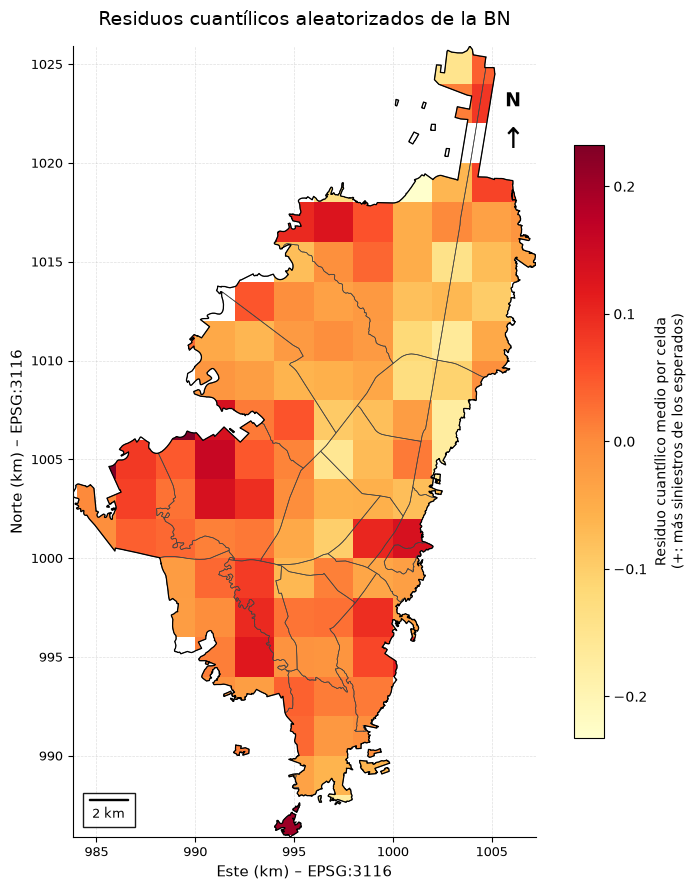

In [17]:

## Figura 6: mapa de residuos cuantílicos aleatorizados de la BN,
## promedio por celda de 2 km


MODELO_MAPA = 'BN'
MIN_SEG_CELDA = 30
CRS_PROY = "EPSG:3116"

# =========================================================
# 1. PREPARACIÓN DE LOS RESIDUOS Y REJILLA
# =========================================================
z_map = rqr(aj[MODELO_MAPA], D, 'tr')

ix = (XY[:, 0] // TAM_BLOQUE_M).astype(int)
iy = (XY[:, 1] // TAM_BLOQUE_M).astype(int)

celdas = (
    pd.DataFrame({'ix': ix, 'iy': iy, 'z': z_map})
    .groupby(['ix', 'iy'])['z']
    .agg(['mean', 'size'])
    .reset_index()
)

celdas.loc[celdas['size'] < MIN_SEG_CELDA, 'mean'] = np.nan

# Rejilla en kilómetros
x_edges = (np.arange(ix.min(), ix.max() + 2) * TAM_BLOQUE_M) / 1000
y_edges = (np.arange(iy.min(), iy.max() + 2) * TAM_BLOQUE_M) / 1000

M = np.full((len(y_edges) - 1, len(x_edges) - 1), np.nan)

M[
    celdas['iy'] - iy.min(),
    celdas['ix'] - ix.min()
] = celdas['mean']


# =========================================================
# 2. PERÍMETRO URBANO Y LOCALIDADES
# =========================================================
perimetro = gpd.read_file('Data/raw/perimetrourbano (1).gpkg')

assert perimetro.crs is not None, 'El perímetro no tiene CRS definido'

perimetro = perimetro.to_crs(CRS_PROY)

perim = perimetro.geometry.buffer(0).union_all()

loc = gpd.read_file('Data/raw/localidades_bogota.gpkg').to_crs(CRS_PROY)

loc_urb = gpd.clip(loc, perim)


# =========================================================
# 3. FUNCIÓN PARA CONVERTIR POLÍGONOS EN PATH
# =========================================================
def poligono_a_path(geom):
    polys = [geom] if geom.geom_type == 'Polygon' else list(geom.geoms)

    verts, codes = [], []

    for p in polys:
        for anillo in [p.exterior, *p.interiors]:
            xy = np.asarray(anillo.coords) / 1000.0

            verts.extend(xy)
            codes.extend(
                [Path.MOVETO] +
                [Path.LINETO] * (len(xy) - 2) +
                [Path.CLOSEPOLY]
            )

    return Path(verts, codes)


# =========================================================
# 4. FIGURA Y MAPA DE RESIDUOS
# =========================================================
lim = np.nanpercentile(np.abs(M), 98)

fig, ax = plt.subplots(figsize=(8, 9))

malla = ax.pcolormesh(
    x_edges,
    y_edges,
    M,
    cmap='YlOrRd',
    norm=mcolors.TwoSlopeNorm(
        vcenter=0,
        vmin=-lim,
        vmax=lim
    ),
    shading='auto',
    zorder=2
)

# Barra de color
cb = fig.colorbar(malla, ax=ax, shrink=0.75)

cb.set_label(
    'Residuo cuantílico medio por celda\n(+: más siniestros de los esperados)',
    fontsize=10
)


# =========================================================
# 5. RECORTE AL PERÍMETRO URBANO
# =========================================================
parche = PathPatch(
    poligono_a_path(perim),
    transform=ax.transData,
    facecolor='none',
    edgecolor='none'
)

ax.add_patch(parche)
malla.set_clip_path(parche)


# =========================================================
# 6. CONTORNOS DE LOCALIDADES Y PERÍMETRO
# =========================================================
loc_urb_km = loc_urb.copy()

loc_urb_km.geometry = loc_urb_km.geometry.scale(
    xfact=1/1000,
    yfact=1/1000,
    origin=(0, 0)
)

loc_urb_km.boundary.plot(
    ax=ax,
    color='#444444',
    linewidth=0.5,
    zorder=3
)

perimetro_km = perimetro.copy()

perimetro_km.geometry = perimetro_km.geometry.scale(
    xfact=1/1000,
    yfact=1/1000,
    origin=(0, 0)
)

perimetro_km.boundary.plot(
    ax=ax,
    color='black',
    linewidth=0.9,
    zorder=4
)


# =========================================================
# 7. LÍMITES Y FORMATO CARTOGRÁFICO
# =========================================================
xmin, ymin, xmax, ymax = perim.bounds

ax.set_xlim(xmin / 1000, xmax / 1000)
ax.set_ylim(ymin / 1000, ymax / 1000)

ax.set_aspect('equal')

ax.set_xlabel('Este (km) – EPSG:3116', fontsize=11)
ax.set_ylabel('Norte (km) – EPSG:3116', fontsize=11)

ax.set_title(
    'Residuos cuantílicos aleatorizados de la BN',
    fontsize=14,
    pad=15
)

ax.grid(
    True,
    linestyle='--',
    linewidth=0.5,
    alpha=0.4,
    zorder=1
)


# =========================================================
# 8. FLECHA DE NORTE
# Mismo estilo de la Figura 2
# =========================================================
ax.annotate(
    'N',
    xy=(0.95, 0.93),
    xycoords='axes fraction',
    ha='center',
    va='center',
    fontsize=14,
    fontweight='bold',
    zorder=6
)

ax.annotate(
    '↑',
    xy=(0.95, 0.88),
    xycoords='axes fraction',
    ha='center',
    va='center',
    fontsize=20,
    zorder=6
)


# =========================================================
# 9. ESCALA GRÁFICA
# Longitud real de 2 km
# =========================================================
escala = AnchoredSizeBar(
    ax.transData,
    2,
    '2 km',
    loc='lower left',
    pad=0.5,
    borderpad=0.8,
    sep=5,
    frameon=True,
    size_vertical=0.04,
    color='black',
    fontproperties=fm.FontProperties(size=9)
)

escala.patch.set_facecolor('white')
escala.patch.set_alpha(0.9)

ax.add_artist(escala)


# =========================================================
# 10. FORMATO FINAL
# =========================================================
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.tick_params(axis='both', labelsize=9)

plt.tight_layout()
plt.show()


## 9. Diagnósticos de ajuste del modelo final

In [18]:
## Frecuencias observadas y esperadas, calibración por deciles, residuos cuantílicos y VIF
m = aj[MODELO_FINAL]
y, X, off, Xi = entradas(m, D, 'tr')
mu = m['media'](X, off, Xi)

K_MAX = 8
esp = [np.exp(m['logpmf'](np.full(len(y), k, float), X, off, Xi)).sum() for k in range(K_MAX)]
esp.append(len(y) - sum(esp))
obs = [(y == k).sum() for k in range(K_MAX)] + [(y >= K_MAX).sum()]
freq = pd.DataFrame({'conteo': [str(k) for k in range(K_MAX)] + [f'>={K_MAX}'], 'observado': obs, 'esperado': np.round(esp, 1)})
freq['obs/esp'] = (freq['observado'] / freq['esperado']).round(3)
print(freq.to_string(index=False))

calib = pd.DataFrame({'mu': mu, 'y': y}).groupby(pd.qcut(mu, 10, duplicates='drop'), observed=True).agg(esperado=('mu', 'mean'), observado=('y', 'mean'), n=('y', 'size'))
print(calib.round(4).to_string())

z = rqr(m, D, 'tr')
print(f"Residuos cuantílicos: media = {z.mean():.3f} | desv. est. = {z.std():.3f} | % con |z| > 3 = {100 * (np.abs(z) > 3).mean():.2f}")

vif = pd.Series([variance_inflation_factor(X.to_numpy(float), i) for i in range(X.shape[1])], index=X.columns).drop('const')
print(vif.round(2).to_string())

## Calibración por deciles de longitud: verificación directa de la especificación de la longitud
dec_len = pd.qcut(np.exp(D['len_tr']), 10)
calib_len = pd.DataFrame({'mu': mu, 'y': y}).groupby(dec_len, observed=True).agg(esperado=('mu', 'mean'), observado=('y', 'mean'), n=('y', 'size'))
calib_len['obs/esp'] = calib_len['observado'] / calib_len['esperado']
print(calib_len.round(4).to_string())

conteo  observado  esperado  obs/esp
     0     118382  118478.5    0.999
     1       9826    9439.8    1.041
     2       2062    2240.2    0.920
     3        729     798.1    0.913
     4        332     348.4    0.953
     5        147     171.3    0.858
     6         85      91.1    0.933
     7         41      51.4    0.798
   >=8        100      85.2    1.174
                   esperado  observado      n
(0.00616, 0.0267]    0.0216     0.0153  13171
(0.0267, 0.0341]     0.0304     0.0231  13170
(0.0341, 0.0435]     0.0386     0.0352  13170
(0.0435, 0.0575]     0.0500     0.0488  13171
(0.0575, 0.0759]     0.0665     0.0658  13170
(0.0759, 0.0997]     0.0867     0.0919  13170
(0.0997, 0.161]      0.1264     0.1522  13171
(0.161, 0.247]       0.2033     0.2265  13170
(0.247, 0.387]       0.3084     0.2979  13170
(0.387, 3.427]       0.6118     0.5646  13171
Residuos cuantílicos: media = 0.002 | desv. est. = 0.997 | % con |z| > 3 = 0.31
dist_puente_peatonal_m      1.42
dist_puente

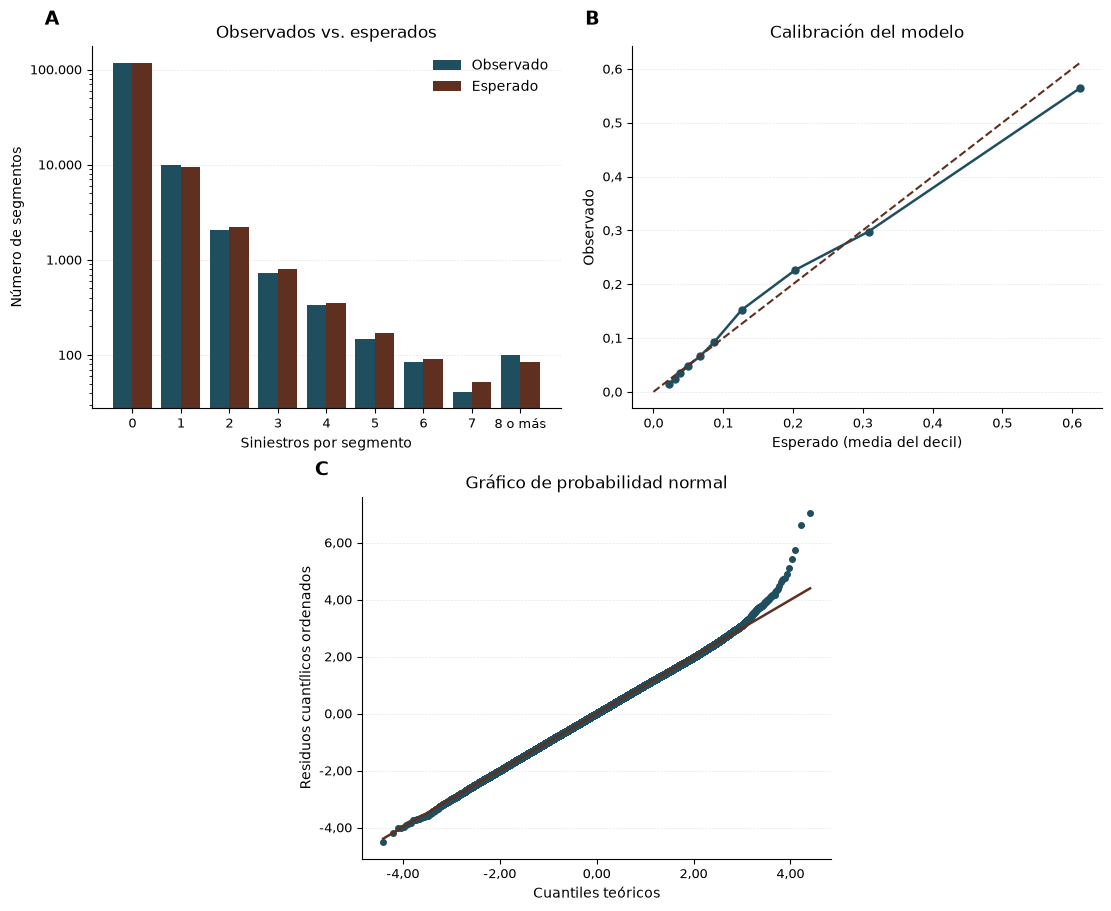

In [19]:

# --- Formato es-CO: punto de miles, coma decimal ---
def fmt_es(dec=0):
    def _f(x, pos=None):
        s = f'{x:,.{dec}f}'
        return s.replace(',', '#').replace('.', ',').replace('#', '.')
    return FuncFormatter(_f)


## Figura 5: distribución en dos filas
fig = plt.figure(figsize=(11, 9), layout='constrained')

gs = fig.add_gridspec(
    2, 4,
    height_ratios=[1, 1],
    width_ratios=[1, 1, 1, 1]
)

ax_a = fig.add_subplot(gs[0, 0:2])
ax_b = fig.add_subplot(gs[0, 2:4])
ax_c = fig.add_subplot(gs[1, 1:3])

axes = [ax_a, ax_b, ax_c]

pos = np.arange(len(freq))

# =========================================================
# (A) OBSERVADOS VS ESPERADOS
# =========================================================
ax_a.bar(
    pos - 0.2, freq['observado'], 0.4,
    label='Observado', color='#1F4E5F', edgecolor='none'
)

ax_a.bar(
    pos + 0.2, freq['esperado'], 0.4,
    label='Esperado', color='#5F301F', edgecolor='none'
)

ax_a.set_yscale('log')
ax_a.yaxis.set_major_formatter(fmt_es(0))
ax_a.yaxis.set_minor_formatter(NullFormatter())

ax_a.set_xticks(pos)

etiquetas = freq['conteo'].astype(str).tolist()
etiquetas[-1] = '8 o más'
ax_a.set_xticklabels(etiquetas)

ax_a.set_xlabel('Siniestros por segmento')
ax_a.set_ylabel('Número de segmentos')
ax_a.set_title('Observados vs. esperados')
ax_a.legend(frameon=False)


# =========================================================
# (B) CALIBRACIÓN
# =========================================================
ax_b.plot(
    calib['esperado'], calib['observado'],
    'o-', color='#1F4E5F', linewidth=1.8, markersize=5
)

ax_b.plot(
    [0, calib['esperado'].max()],
    [0, calib['esperado'].max()],
    '--', color='#5F301F', linewidth=1.5
)

ax_b.xaxis.set_major_formatter(fmt_es(1))
ax_b.yaxis.set_major_formatter(fmt_es(1))

ax_b.set_xlabel('Esperado (media del decil)')
ax_b.set_ylabel('Observado')
ax_b.set_title('Calibración del modelo')


# =========================================================
# (C) QQ DE RESIDUOS CUANTÍLICOS
# =========================================================
stats.probplot(z, dist='norm', plot=ax_c)

ax_c.get_lines()[0].set_color('#1F4E5F')
ax_c.get_lines()[0].set_markerfacecolor('#1F4E5F')
ax_c.get_lines()[0].set_markeredgecolor('#1F4E5F')
ax_c.get_lines()[0].set_markersize(4)

ax_c.get_lines()[1].set_color('#5F301F')
ax_c.get_lines()[1].set_linewidth(1.8)

ax_c.xaxis.set_major_formatter(fmt_es(2))
ax_c.yaxis.set_major_formatter(fmt_es(2))

ax_c.set_title('Gráfico de probabilidad normal')
ax_c.set_xlabel('Cuantiles teóricos')
ax_c.set_ylabel('Residuos cuantílicos ordenados')


# =========================================================
# FORMATO GENERAL
# =========================================================
for i, a in enumerate(axes):
    a.text(
        -0.10, 1.10,
        ['A', 'B', 'C'][i],
        transform=a.transAxes,
        fontsize=14,
        fontweight='bold',
        va='top'
    )

    a.tick_params(axis='both', labelsize=9)
    a.grid(axis='y', linestyle='--', linewidth=0.5, alpha=0.3)
    a.set_axisbelow(True)

    a.spines['top'].set_visible(False)
    a.spines['right'].set_visible(False)

plt.show()



## 10. Modelo final: tabla completa de coeficientes con errores estándar agrupados

In [20]:
## Tabla del modelo final: EE del modelo, robustos (HC0) y agrupados por celda espacial; con ZINB se recalcula la covarianza conjunta (inflación, conteo y alpha) en el óptimo ya estimado
X, y, off, Xi = D['X_tr'], D['y_tr'], D['off_tr'], D['Xi_tr']

if MODELO_FINAL == 'ZINB':
    mod = ZeroInflatedNegativeBinomialP(y, X, exog_infl=Xi, offset=off, inflation='logit', p=2)
    p0 = _num(aj['ZINB']['res'].params)
    # maxiter=0 no reestima: deja los parámetros en p0 y solo cambia el estimador de la covarianza
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')    # maxiter=0 siempre dispara ConvergenceWarning aunque p0 ya sea el óptimo
        f_mod, f_hc0, f_cl = (mod.fit(start_params=p0, method='bfgs', maxiter=0, disp=0, **kw)
                              for kw in ({}, {'cov_type': 'HC0'}, {'cov_type': 'cluster', 'cov_kwds': {'groups': celda}}))
    assert np.allclose(_num(f_cl.params), p0), 'La covarianza agrupada no debe mover los parámetros'
    comp = ['inflación'] * Xi.shape[1] + ['conteo'] * (len(p0) - Xi.shape[1] - 1) + ['dispersión']
elif MODELO_FINAL == 'BN':
    mod = sm.NegativeBinomial(y, X, offset=off, loglike_method='nb2')
    p0 = _num(aj['BN']['params'])    # [coeficientes, alpha] con el alpha de perfil; la covarianza conjunta sí incluye la incertidumbre de alpha
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')    # maxiter=0 siempre dispara ConvergenceWarning aunque p0 ya sea el óptimo
        f_mod, f_hc0, f_cl = (mod.fit(start_params=p0, method='bfgs', maxiter=0, disp=0, **kw)
                              for kw in ({}, {'cov_type': 'HC0'}, {'cov_type': 'cluster', 'cov_kwds': {'groups': celda}}))
    assert np.allclose(_num(f_cl.params), p0), 'La covarianza agrupada no debe mover los parámetros'
    comp = ['conteo'] * (len(p0) - 1) + ['dispersión']
else:
    mod = sm.GLM(y, X, family=sm.families.Poisson(), offset=off)
    f_mod, f_hc0, f_cl = mod.fit(), mod.fit(cov_type='HC0'), mod.fit(cov_type='cluster', cov_kwds={'groups': celda})
    comp = ['conteo'] * len(f_cl.params)

est, ee = _num(f_cl.params), _num(f_cl.bse)
es_alpha = np.array(comp) == 'dispersión'
inf_, sup_ = est - 1.96 * ee, est + 1.96 * ee
if es_alpha.any():
    # alpha > 0: el IC se arma en escala log con el método delta (EE de log(alpha) = EE / alpha)
    inf_[es_alpha] = est[es_alpha] * np.exp(-1.96 * ee[es_alpha] / est[es_alpha])
    sup_[es_alpha] = est[es_alpha] * np.exp(1.96 * ee[es_alpha] / est[es_alpha])

tab = pd.DataFrame({'componente': comp, 'coef': est, 'EE modelo': _num(f_mod.bse), 'EE HC0': _num(f_hc0.bse), 'EE agrupado': ee}, index=f_cl.params.index)
tab['razón'] = np.where(es_alpha, est, np.exp(est))    # IRR en el conteo, razón de odds en la inflación, alpha tal cual
tab['IC95 inf'] = np.where(es_alpha, inf_, np.exp(inf_))
tab['IC95 sup'] = np.where(es_alpha, sup_, np.exp(sup_))
tab['p agrupado'] = np.where(es_alpha, np.nan, 2 * stats.norm.sf(np.abs(est / ee)))    # alpha = 0 está en la frontera: el Wald no aplica

print(f"Modelo final: {MODELO_FINAL} | longitud: {'libre' if LONGITUD_LIBRE else 'offset'} | celdas (grupos): {len(np.unique(celda))} | convergió: {aj[MODELO_FINAL]['convergio']}")
print(tab.round(4).to_string())

Modelo final: BN | longitud: libre | celdas (grupos): 132 | convergió: True
                          componente    coef  EE modelo  EE HC0  EE agrupado   razón  IC95 inf  IC95 sup  p agrupado
const                         conteo -2.8685     0.0298  0.0318       0.0637  0.0568    0.0501    0.0643      0.0000
dist_puente_peatonal_m        conteo -0.0203     0.0093  0.0107       0.0225  0.9799    0.9376    1.0241      0.3667
dist_puente_vehicular_m       conteo  0.0791     0.0094  0.0110       0.0223  1.0823    1.0360    1.1306      0.0004
dist_semaforo_m               conteo -0.2478     0.0088  0.0095       0.0244  0.7806    0.7441    0.8188      0.0000
ratio_cobertura_peatonal      conteo  0.7039     0.0120  0.0131       0.0249  2.0216    1.9252    2.1229      0.0000
MVINUMC                       conteo  0.2133     0.0142  0.0169       0.0253  1.2377    1.1778    1.3006      0.0000
log_long                      conteo  0.5044     0.0132  0.0163       0.0218  1.6560    1.5868    1.7282 

In [21]:
## Elasticidad de la frecuencia esperada respecto de la longitud: en el ZINB la longitud entra al conteo y a la inflación, así que el coeficiente de log_long no es la elasticidad total
sd_l = OFF_LEN.std()    # misma desviación que usa armar_disenio con todos los segmentos

if MODELO_FINAL == 'ZINB':
    k_inf, Xn, Xi_n = Xi.shape[1], _num(X), _num(Xi)
    j_len = list(X.columns).index('log_long') if LONGITUD_LIBRE else None

    def elast_media(p):
        # E[y] = (1 - pi) * mu, entonces d log E / d log L = (beta_long, o 1 con offset) - g1 / sd_l * pi, promediado entre segmentos
        g, b = p[:k_inf], p[k_inf:-1]
        return (b[j_len] if LONGITUD_LIBRE else 1.0) - g[1] / sd_l * expit(Xi_n @ g).mean()

    sim = np.random.default_rng(SEMILLA).multivariate_normal(p0, _num(f_cl.cov_params()), N_SIM)    # Krinsky-Robb con la covarianza agrupada
    e_sim = np.array([elast_media(s) for s in sim])
    print(f"Elasticidad total media: {elast_media(p0):.3f} (IC95 % simulado {np.percentile(e_sim, 2.5):.3f} a {np.percentile(e_sim, 97.5):.3f})")
    if LONGITUD_LIBRE:
        print(f"Coeficiente de log_long en el conteo: {tab.loc['log_long', 'coef']:.3f} (EE agrupado {tab.loc['log_long', 'EE agrupado']:.3f})")
elif LONGITUD_LIBRE:
    e, s = tab.loc['log_long', 'coef'], tab.loc['log_long', 'EE agrupado']    # aquí el coeficiente sí es la elasticidad
    print(f"Elasticidad: {e:.3f} (IC95 % agrupado {e - 1.96 * s:.3f} a {e + 1.96 * s:.3f})")
else:
    print('Con offset la elasticidad está fijada en 1')

Elasticidad: 0.504 (IC95 % agrupado 0.462 a 0.547)


## 11. Sensibilidad: longitud como offset frente a covariable libre (Poisson, BN y ZINB)

In [22]:
## Se ajustan los tres modelos con offset y con longitud libre; la especificación activa ya está ajustada (aj) y solo se ajusta la otra
D_esp, aj_esp = {LONGITUD_LIBRE: D}, {LONGITUD_LIBRE: aj}
otra = not LONGITUD_LIBRE
D_esp[otra] = armar_disenio(pos_all, pos_all, libre=otra)
aj_esp[otra] = ajustar_todos(D_esp[otra])

comp_esp = pd.DataFrame([dict(especificacion='longitud libre' if lib else 'offset', modelo=nom, parametros=m['k'], logLik=m['llf'], AIC=m['aic'], BIC=m['bic'], alpha=m['alpha'], convergio=m['convergio'])
                         for lib in (False, True) for nom, m in aj_esp[lib].items() if nom != 'Nulo']).set_index(['especificacion', 'modelo'])
print(comp_esp.round(2).to_string())

## Razón de verosimilitud de la elasticidad = 1 (el offset está anidado en la longitud libre); ignora la dependencia espacial, por eso sobrestima la significancia
for nom in ('Poisson', 'BN', 'ZINB'):
    lr = 2 * (aj_esp[True][nom]['llf'] - aj_esp[False][nom]['llf'])
    print(f"{nom}: LR = {lr:.1f} (1 gl, p = {stats.chi2.sf(lr, 1):.3g})")

## Elasticidad de la BN con EE agrupado (alpha fijo) y razones de tasas con cada especificación
D_l, bn_l = D_esp[True], aj_esp[True]['BN']
f_l = sm.GLM(D_l['y_tr'], D_l['X_tr'], family=sm.families.NegativeBinomial(alpha=bn_l['alpha']), offset=D_l['off_tr']).fit(cov_type='cluster', cov_kwds={'groups': celda})
el, ic = f_l.params['log_long'], f_l.conf_int().loc['log_long']
print(f"Elasticidad con la longitud (BN): {el:.3f} (IC95 % agrupado {ic[0]:.3f} a {ic[1]:.3f}); el offset supone 1.000")
print(pd.DataFrame({'IRR offset': np.exp(aj_esp[False]['BN']['res'].params), 'IRR longitud libre': np.exp(bn_l['res'].params.drop('log_long'))}).round(3).to_string())

                        parametros    logLik        AIC        BIC  alpha  convergio
especificacion modelo                                                               
offset         Poisson           7 -55954.49  111922.98  111991.50    NaN       True
               BN                8 -50374.50  100765.01  100843.32   3.17       True
               ZINB             10 -50271.99  100563.97  100661.86   2.25       True
longitud libre Poisson           8 -54712.71  109441.42  109519.73    NaN       True
               BN                9 -49735.53   99489.06   99577.16   2.83       True
               ZINB             11 -49732.73   99487.45   99595.12   2.68       True
Poisson: LR = 2483.6 (1 gl, p = 0)
BN: LR = 1277.9 (1 gl, p = 7.02e-280)
ZINB: LR = 1078.5 (1 gl, p = 1.54e-236)
Elasticidad con la longitud (BN): 0.504 (IC95 % agrupado 0.461 a 0.547); el offset supone 1.000
                          IRR offset  IRR longitud libre
const                          0.001               0.0

In [23]:
## Validación por bloques de las dos especificaciones con los tres modelos; la de la especificación activa ya está calculada (cv_bloques)
def etiqueta(lib):
    return 'bloques, longitud libre' if lib else 'bloques, offset'


cv_len = {LONGITUD_LIBRE: cv_bloques.assign(esquema=etiqueta(LONGITUD_LIBRE))}
cv_len[otra] = validar(part_bloques, etiqueta(otra), otra)
cmp_len = pd.concat(cv_len.values()).query("modelo in ['Poisson', 'BN', 'ZINB']").groupby(['esquema', 'modelo'])[['devianza', 'logscore', 'dev_explicada']].mean()
print(cmp_len.round(4).to_string())

bloques, offset: pliegue 1/5 listo
bloques, offset: pliegue 2/5 listo
bloques, offset: pliegue 3/5 listo
bloques, offset: pliegue 4/5 listo
bloques, offset: pliegue 5/5 listo
                                 devianza  logscore  dev_explicada
esquema                 modelo                                    
bloques, longitud libre BN         0.6073   -0.3781         0.1861
                        Poisson    0.6068   -0.4162         0.1868
                        ZINB       0.6075   -0.3781         0.1858
bloques, offset         BN         0.6300   -0.3829         0.1557
                        Poisson    0.6255   -0.4255         0.1618
                        ZINB       0.6194   -0.3822         0.1700


In [24]:
## Regla para la longitud, fijada después de ver estos resultados (el texto debe decirlo): libre si el offset se rechaza y la libre mejora BIC, log-score y devianza por bloques, en BN y en ZINB
criterios = {}
for nom in ('BN', 'ZINB'):
    lr = 2 * (aj_esp[True][nom]['llf'] - aj_esp[False][nom]['llf'])
    lib, off_ = cmp_len.loc[(etiqueta(True), nom)], cmp_len.loc[(etiqueta(False), nom)]
    criterios[nom] = dict(LR_rechaza=bool(stats.chi2.sf(lr, 1) < 0.05),
                          BIC=bool(comp_esp.loc[('longitud libre', nom), 'BIC'] < comp_esp.loc[('offset', nom), 'BIC']),
                          logscore=bool(lib['logscore'] > off_['logscore']),
                          devianza=bool(lib['devianza'] < off_['devianza']))
res_regla = pd.DataFrame(criterios).T
print(res_regla.to_string())

LIBRE_JUSTIFICADA = bool(res_regla.to_numpy().all())
print(f"Longitud libre justificada: {LIBRE_JUSTIFICADA} | LONGITUD_LIBRE activo: {LONGITUD_LIBRE}")
if LIBRE_JUSTIFICADA != LONGITUD_LIBRE:
    warnings.warn('LONGITUD_LIBRE no coincide con la regla: hay que re-ejecutar todo el cuaderno con el valor que la regla indica')

      LR_rechaza   BIC  logscore  devianza
BN          True  True      True      True
ZINB        True  True      True      True
Longitud libre justificada: True | LONGITUD_LIBRE activo: True


## 12. Conclusiones

### Del modelo (valores de la ejecución v5; verificar contra las salidas al re-ejecutar)
- **Modelo final:** binomial negativa con log(longitud) como covariable libre, α ≈ 2,83. El ZINB no mejora a la BN en BIC, log-score ni devianza, por lo que la regla declarada conserva la BN.
- **Longitud:** la elasticidad de la frecuencia esperada respecto de la longitud es ≈ 0,50 (IC95 % ≈ 0,46 a 0,55); el offset de coeficiente 1 queda rechazado. La especificación de la longitud se decidió después de ver la sensibilidad y el texto debe declararlo.
- **Desempeño:** moderado. Devianza explicada ≈ 18,8 % (validación aleatoria) y ≈ 18,6 % (bloques de 2 km); casi no cae al predecir en celdas no vistas. El I de Moran de los residuales es ≈ 0,02 y se concentra en distancias cortas.
- **Calibración en S:** el modelo sobreestima los deciles bajos y subestima los intermedios (7 y 8). Conserva el orden de las frecuencias por decil, no los niveles absolutos.
- **Sin exposición peatonal real:** la cobertura peatonal (IRR ≈ 2) actúa como proxy de actividad; calzadas y velocidad pueden reflejar jerarquía vial y no un efecto causal de la infraestructura.

### De la priorización (se cumplen por construcción del Bayes empírico con la BN)
1. El exceso esperado es (1 − w)(y − μ): solo es positivo donde el conteo observado supera a la frecuencia predicha. Un segmento sin siniestros registrados nunca tiene exceso positivo, y su frecuencia esperada con Bayes empírico no supera 1/α.
2. Por eso el % de segmentos sin siniestros es ≈ 0 en el escenario C y bajo en B, y no es un hallazgo empírico. La capacidad de señalar segmentos de riesgo estimado alto sin historial es propia del escenario A; el contraste A frente a C es el que informa.
3. Con α alto el peso de la FDS (w) es bajo en los segmentos de μ alto: B y C dependen sobre todo del conteo observado, y por tanto de la regla de asignación de siniestros a segmentos y del subregistro. Por la misma razón B y C tienden a coincidir entre sí y a separarse de A.
4. La correlación de rangos entre A y C en la red completa es negativa por construcción (entre los segmentos sin siniestros, mayor μ implica exceso más negativo); solo es interpretable entre segmentos con siniestros.
5. A usa solo el orden de μ; B y C usan sus niveles, que están afectados por la calibración en S. La tabla de composición por decil de μ muestra cuánto.
6. La lista indica dónde se espera mayor frecuencia de siniestros peatonales, no dónde la infraestructura es peor. El orden por segmento favorece tramos largos (μ crece con la longitud); la sensibilidad por kilómetro cuantifica ese efecto.
7. La severidad describe a los priorizados y no entra al orden: la priorización trata todos los siniestros como equivalentes y puede subponderar segmentos poco frecuentes pero con alta letalidad (línea futura).

### Limitaciones que hereda la priorización
FDS estimada y aplicada sobre la misma red (predicción dentro de muestra), α constante frente a la longitud, regla de asignación de siniestros a segmentos (empates en intersecciones), subregistro de siniestros, infraestructura vigente frente a siniestros 2015–2020, y tamaño del top-N (1 %, 5 % y 10 %) definido por convención y no por presupuesto.

In [27]:
## Guardado del modelo final y de todo lo que la priorización (sección 12 en adelante) necesita


CARPETA_MODELO = 'Data/processed/modelo_fds'
os.makedirs(CARPETA_MODELO, exist_ok=True)

if MODELO_FINAL != 'BN':
    warnings.warn(f'MODELO_FINAL es {MODELO_FINAL}: la priorización de la sección 12 exige la BN y su assert fallará')
if LIBRE_JUSTIFICADA != LONGITUD_LIBRE:
    warnings.warn('LONGITUD_LIBRE no coincide con la regla de la sección 11: lo guardado corresponde a la especificación activa')

bn = aj['BN']
mu_bruta = bn['media'](D['X_tr'], D['off_tr'], D['Xi_tr'])    # predicción sin calibrar, en el orden de df_unificado
assert len(mu_bruta) == len(df_unificado) and np.isfinite(mu_bruta).all()

## Referencia por segmento: sirve para verificar que el cuaderno 2 lee el mismo conjunto, en el mismo orden
pred = pd.DataFrame({'pos': pos_all, COL_X: df_unificado[COL_X].to_numpy(float), COL_Y: df_unificado[COL_Y].to_numpy(float),
                     'long_seg_m': df_unificado['long_seg_m'].to_numpy(float),
                     'n_siniestros': df_unificado['n_siniestros'].to_numpy(float), 'mu_bruta': mu_bruta})
if 'seg_id' in df_unificado.columns:
    pred.insert(1, 'seg_id', df_unificado['seg_id'].to_numpy())
pred.to_csv(f'{CARPETA_MODELO}/predicciones_bn.csv', index=False)

## Paquete del modelo: solo DataFrames, arreglos y números (nada de funciones, que pickle no guarda)
paquete = dict(params_bn=_num(bn['params']),    # [coeficientes..., alpha]
               X_tr=D['X_tr'], Xi_tr=D['Xi_tr'], off_tr=D['off_tr'], len_tr=D['len_tr'],
               mu_bruta=mu_bruta, pred=pred, tab=tab, celda=celda, fold_bloque=fold_bloque)
joblib.dump(paquete, f'{CARPETA_MODELO}/modelo_bn.joblib', compress=3)

## Configuración legible
config = dict(fecha=datetime.now().isoformat(timespec='seconds'),
              SEMILLA=SEMILLA, K_PLIEGUES=K_PLIEGUES, LONGITUD_LIBRE=bool(LONGITUD_LIBRE),
              COL_X=COL_X, COL_Y=COL_Y, TAM_BLOQUE_M=TAM_BLOQUE_M, K_VECINOS=K_VECINOS,
              BASE=BASE, MODELO_FINAL=MODELO_FINAL, LIBRE_JUSTIFICADA=bool(LIBRE_JUSTIFICADA),
              alpha_bn=float(bn['alpha']), n_segmentos=int(len(df_unificado)), n_siniestros=float(Y_ALL.sum()),
              columnas_X=list(D['X_tr'].columns), columnas_Xi=list(D['Xi_tr'].columns),
              archivo_datos='Data/processed/segmentos_unificado.csv',
              versiones=dict(python=sys.version.split()[0], numpy=np.__version__, pandas=pd.__version__,
                             statsmodels=statsmodels.__version__, sklearn=sklearn.__version__))
with open(f'{CARPETA_MODELO}/config.json', 'w', encoding='utf-8') as f:
    json.dump(config, f, indent=2, ensure_ascii=False)

## Tablas de las secciones 6 a 11 para el texto de la tesis (no las necesita el cuaderno 2)
tab.to_csv(f'{CARPETA_MODELO}/tabla_coeficientes.csv')
tabla_cv.to_csv(f'{CARPETA_MODELO}/validacion_cruzada.csv')
comp_esp.to_csv(f'{CARPETA_MODELO}/sensibilidad_longitud_ajuste.csv')
cmp_len.to_csv(f'{CARPETA_MODELO}/sensibilidad_longitud_validacion.csv')
res_regla.to_csv(f'{CARPETA_MODELO}/regla_longitud.csv')

print('Guardado en', CARPETA_MODELO)
for nombre in sorted(os.listdir(CARPETA_MODELO)):
    print(f'  {nombre:45s} {os.path.getsize(os.path.join(CARPETA_MODELO, nombre)) / 1e6:8.2f} MB')

Guardado en Data/processed/modelo_fds
  config.json                                       0.00 MB
  modelo_bn.joblib                                 10.50 MB
  predicciones_bn.csv                              11.28 MB
  regla_longitud.csv                                0.00 MB
  sensibilidad_longitud_ajuste.csv                  0.00 MB
  sensibilidad_longitud_validacion.csv              0.00 MB
  tabla_coeficientes.csv                            0.00 MB
  validacion_cruzada.csv                            0.00 MB
